# Datathon Deep Learning – Tim T017
Notebook ini disusun mengikuti **alur kerja 6 fase** dari ketentuan.

## Fase 0 – Setup

In [1]:
import os, glob, time, random, json, shutil, joblib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# Sembunyikan GPU: data kecil (CPU cukup) dan menghindari error CUDA 303 di Kaggle
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

warnings.filterwarnings('ignore')

TEAM, SEED = 'T017', 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
set_seed()

# --- Folder proyek (output Kaggle) ---
PROJECT = f'/kaggle/working/datathon_{TEAM}'
for sub in ['code', 'models', 'predictions', 'figures']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)

# --- Lokasi Dataset C ---
DATA_ROOT = '/kaggle/input/datasets/sellyrk/dataset-datathon/student'
folder_c = f'{DATA_ROOT}/dataset_C'
if not os.path.isdir(folder_c):                      # cadangan: cari otomatis
    hits = glob.glob('/kaggle/input/**/dataset_C', recursive=True)
    if not hits:
        raise FileNotFoundError('Folder dataset_C tidak ditemukan di /kaggle/input. Pastikan dataset sudah di-Add Input.')
    folder_c = hits[0]

def pick(pattern):
    m = sorted(glob.glob(f'{folder_c}/{pattern}'))
    return m[0] if m else None

train_path, test_path, sample_path = pick('train*.csv'), pick('test*.csv'), pick('sample_submission*.csv')
assert train_path and test_path, 'train/test Dataset C tidak ditemukan'
train_df, test_df = pd.read_csv(train_path), pd.read_csv(test_path)

print('Folder  :', folder_c)
print('Train   :', os.path.basename(train_path), train_df.shape, 'OK' if train_df.shape == (9600, 5) else '(PERIKSA: diharapkan (9600, 5))')
print('Test    :', os.path.basename(test_path), test_df.shape, 'OK' if test_df.shape == (2400, 4) else '(PERIKSA: diharapkan (2400, 4))')
print('Sample  :', os.path.basename(sample_path) if sample_path else 'TIDAK ADA')
print('PROJECT :', PROJECT, '->', sorted(os.listdir(PROJECT)))

Folder  : /kaggle/input/datasets/sellyrk/dataset-datathon/student/dataset_C
Train   : train_C.csv (9600, 5) OK
Test    : test_C.csv (2400, 4) OK
Sample  : sample_submission_C.csv
PROJECT : /kaggle/working/datathon_T017 -> ['code', 'figures', 'models', 'predictions']


## Fase 1 – Exploratory Data Analysis (EDA)

===== EDA DATASET C =====
Train: (9600, 5) | Test: (2400, 4)
Jumlah fitur       : 3 -> ['feature_01', 'feature_02', 'feature_03']
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    64.47
1    35.53

Statistik fitur:


,mean,std,min,max
feature_01,0.506,0.708,-1.562,2.498
feature_02,-1.464,1.914,-6.123,3.304
feature_03,2.017,1.559,-1.847,5.839


Korelasi antar fitur:


,feature_01,feature_02,feature_03
feature_01,1.000,-0.005,-0.004
feature_02,-0.005,1.000,0.012
feature_03,-0.004,0.012,1.000


Rata-rata fitur per kelas:


,feature_01,feature_02,feature_03
target,,,
0,0.528,-1.945,2.567
1,0.464,-0.591,1.018


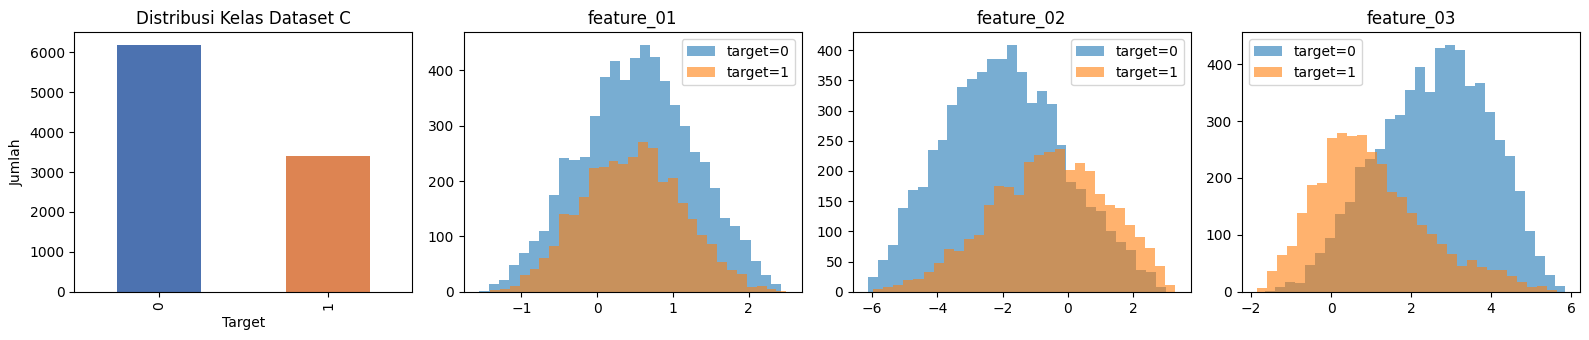

,dataset,n_train,n_test,n_features,missing_train,missing_test,n_classes,majority_class_pct,minority_class_pct,imbalance_ratio
0,C,9600,2400,3,0,0,2,64.47,35.53,1.81


In [2]:
feats = [c for c in train_df.columns if c not in ('sample_id', 'target')]
cls_dist = train_df['target'].value_counts(normalize=True).sort_index()

print('===== EDA DATASET C =====')
print('Train:', train_df.shape, '| Test:', test_df.shape)
print(f'Jumlah fitur       : {len(feats)} -> {feats}')
print('Missing train/test :', int(train_df.isna().sum().sum()), '/', int(test_df.isna().sum().sum()))
print('Duplikat baris     :', int(train_df[feats].duplicated().sum()))
print('Kolom konstan      :', [c for c in feats if train_df[c].nunique() <= 1])
print('Kolom test = train :', set(test_df.columns) == set(feats) | {'sample_id'})
print('Distribusi kelas (%):'); print((cls_dist * 100).round(2).to_string())
print('\nStatistik fitur:'); display(train_df[feats].describe().T[['mean', 'std', 'min', 'max']].round(3))
print('Korelasi antar fitur:'); display(train_df[feats].corr().round(3))
print('Rata-rata fitur per kelas:'); display(train_df.groupby('target')[feats].mean().round(3))

fig, axs = plt.subplots(1, len(feats) + 1, figsize=(4 * (len(feats) + 1), 3.5))
train_df['target'].value_counts().sort_index().plot(kind='bar', ax=axs[0], color=['#4C72B0', '#DD8452'])
axs[0].set_title('Distribusi Kelas Dataset C'); axs[0].set_xlabel('Target'); axs[0].set_ylabel('Jumlah')
for ax, f in zip(axs[1:], feats):
    for k in sorted(train_df['target'].unique()):
        ax.hist(train_df.loc[train_df['target'] == k, f], bins=30, alpha=0.6, label=f'target={k}')
    ax.set_title(f); ax.legend()
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/eda_C.png', dpi=150, bbox_inches='tight'); plt.show()

eda_df = pd.DataFrame([dict(dataset='C', n_train=len(train_df), n_test=len(test_df), n_features=len(feats),
                            missing_train=int(train_df.isna().sum().sum()), missing_test=int(test_df.isna().sum().sum()),
                            n_classes=train_df['target'].nunique(), majority_class_pct=round(cls_dist.max() * 100, 2),
                            minority_class_pct=round(cls_dist.min() * 100, 2), imbalance_ratio=round(cls_dist.max() / cls_dist.min(), 2))])
eda_df.to_csv(f'{PROJECT}/eda_summary_C.csv', index=False)
eda_df

## Fase 2 – Preprocessing & Pembagian Data (80:20)

In [3]:
X = train_df.drop(columns=['sample_id', 'target'])          # sample_id TIDAK jadi fitur
X_test = test_df.drop(columns=['sample_id'])
le = LabelEncoder().fit(train_df['target'])
y = le.transform(train_df['target'])

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

scaler = StandardScaler()
Xtr_s  = scaler.fit_transform(X_tr).astype('float32')       # fit HANYA di train
Xval_s = scaler.transform(X_val).astype('float32')
Xte_s  = scaler.transform(X_test).astype('float32')

joblib.dump(scaler, f'{PROJECT}/models/preprocessor_c.pkl')
joblib.dump(le,     f'{PROJECT}/models/labelencoder_c.pkl')

DATA = {'C': dict(Xtr=Xtr_s, Xval=Xval_s, Xte=Xte_s, ytr=y_tr, yval=y_val, le=le,
                  test_ids=test_df['sample_id'].values, n_classes=len(le.classes_))}
d = DATA['C']
print(f"Train {Xtr_s.shape} | Val {Xval_s.shape} | Test {Xte_s.shape} | kelas {list(le.classes_)}")

Train (7680, 3) | Val (1920, 3) | Test (2400, 3) | kelas [np.int64(0), np.int64(1)]


## Fase 3 – Hyperparameter Tuning

===== EKSPERIMEN MODEL DATASET C =====


2026-10-22 06:27:56.508928: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Config_1_Baseline        val_acc=0.8578 | val_err=0.1422 | epoch=39 | 24.4s
Config_2_Deeper          val_acc=0.8594 | val_err=0.1406 | epoch=37 | 15.6s
Config_3_Tuned_C_Orig    val_acc=0.8609 | val_err=0.1391 | epoch=42 | 19.4s

--> TERBAIK (acuan fallback): Config_3_Tuned_C_Orig (0.8609)


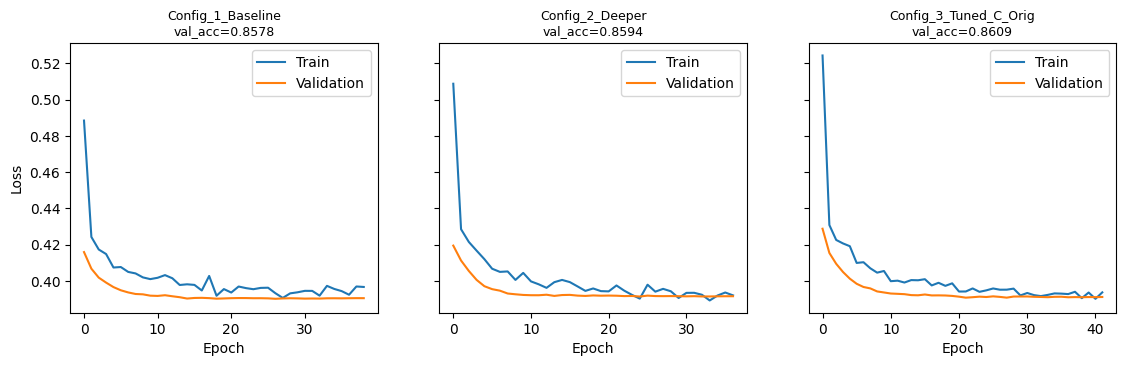

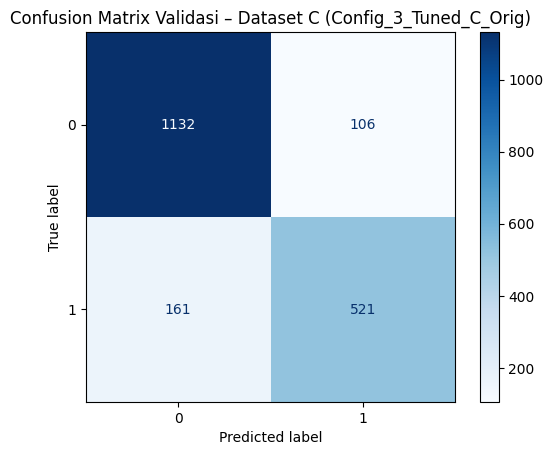

,dataset,config_name,seed,val_accuracy,val_error,training_time
0,C,Config_1_Baseline,42,0.85781,0.14219,24.39
1,C,Config_2_Deeper,42,0.85938,0.14062,15.57
2,C,Config_3_Tuned_C_Orig,42,0.86094,0.13906,19.42


In [4]:
CFG1 = dict(name='Config_1_Baseline',      layers=[64, 32],       act='relu', dropout=0.3, lr=1e-3, batch=32,
            opt='adam', bn=False, epochs=100, patience=12, lr_patience=4)
CFG2 = dict(name='Config_2_Deeper',        layers=[128, 64, 32],  act='relu', dropout=0.2, lr=5e-4, batch=64,
            opt='adam', bn=False, epochs=100, patience=12, lr_patience=4)
CFG3 = dict(name='Config_3_Tuned_C_Orig',  layers=[128, 128, 128], act='relu', dropout=0.3, lr=3e-4, batch=64,
            opt='adam', bn=False, epochs=300, patience=20, lr_patience=6)      # hasil tuning sebelumnya
CONFIGS_C = [CFG1, CFG2, CFG3]

def build_model(n_feat, c):
    m = models.Sequential([layers.Input(shape=(n_feat,))])
    for u in c['layers']:
        m.add(layers.Dense(u))
        if c.get('bn', False): m.add(layers.BatchNormalization())
        m.add(layers.Activation(c['act']))
        m.add(layers.Dropout(c['dropout']))
    m.add(layers.Dense(1, activation='sigmoid'))
    opt = (tf.keras.optimizers.AdamW(learning_rate=c['lr'], weight_decay=1e-4) if c['opt'] == 'adamw'
           else tf.keras.optimizers.Adam(learning_rate=c['lr']))
    m.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return m

rows, RESULTS_C = [], []
print('===== EKSPERIMEN MODEL DATASET C =====')
for c in CONFIGS_C:
    set_seed()
    model = build_model(d['Xtr'].shape[1], c)
    cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=c['patience'], restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=c['lr_patience'], min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(d['Xtr'], d['ytr'], validation_data=(d['Xval'], d['yval']),
                  epochs=c['epochs'], batch_size=c['batch'], callbacks=cbs, verbose=0)
    t_train = time.time() - t0
    raw_preds = model.predict(d['Xval'], verbose=0).ravel()
    vpred = (raw_preds > 0.5).astype(int)
    acc = accuracy_score(d['yval'], vpred)
    print(f"{c['name']:<24} val_acc={acc:.4f} | val_err={1-acc:.4f} | epoch={len(h.history['loss'])} | {t_train:.1f}s")

    rows.append(dict(dataset='C', config_name=c['name'], seed=SEED, val_accuracy=round(acc, 5), val_error=round(1 - acc, 5),
                     training_time=round(t_train, 2), hidden_layers=str(c['layers']), activation=c['act'], dropout=c['dropout'],
                     learning_rate=c['lr'], batch_size=c['batch'], optimizer=c['opt'], epochs_run=len(h.history['loss'])))
    RESULTS_C.append(dict(cfg=c, model=model, hist=h.history, raw_preds=raw_preds, vpred=vpred, acc=acc))

# Model terbaik sebelum tuning lanjutan = acuan/fallback
best = max(RESULTS_C, key=lambda r: r['acc'])
PREV_BEST = best
best['model'].save(f"{PROJECT}/models/model_c_best.keras")
print(f"\n--> TERBAIK (acuan fallback): {best['cfg']['name']} ({best['acc']:.4f})")

fig, axs = plt.subplots(1, len(RESULTS_C), figsize=(4.5 * len(RESULTS_C), 3.5), sharey=True)
for ax, r in zip(axs, RESULTS_C):
    ax.plot(r['hist']['loss'], label='Train'); ax.plot(r['hist']['val_loss'], label='Validation')
    ax.set_title(f"{r['cfg']['name']}\nval_acc={r['acc']:.4f}", fontsize=9); ax.set_xlabel('Epoch'); ax.legend()
axs[0].set_ylabel('Loss')
plt.savefig(f'{PROJECT}/figures/loss_C.png', dpi=150, bbox_inches='tight'); plt.show()

ConfusionMatrixDisplay(confusion_matrix(d['yval'], best['vpred'])).plot(cmap='Blues')
plt.title(f"Confusion Matrix Validasi – Dataset C ({best['cfg']['name']})")
plt.savefig(f'{PROJECT}/figures/cm_C.png', dpi=150, bbox_inches='tight'); plt.show()

exp_df = pd.DataFrame(rows)
exp_df.to_csv(f'{PROJECT}/experiments.csv', index=False)
exp_df[['dataset', 'config_name', 'seed', 'val_accuracy', 'val_error', 'training_time']]

### Fase 3b – Pembanding Non-Deep-Learning (hanya untuk laporan)

In [5]:
from sklearn.ensemble import RandomForestClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

cmp_rows = []
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(d['Xtr'], d['ytr'])
cmp_rows.append(dict(dataset='C', model='RandomForest (pembanding)', val_accuracy=accuracy_score(d['yval'], rf.predict(d['Xval'])),
                     time_s=round(time.time() - t0, 1)))
if HAS_XGB:
    t0 = time.time()
    xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1).fit(d['Xtr'], d['ytr'])
    cmp_rows.append(dict(dataset='C', model='XGBoost (pembanding)', val_accuracy=accuracy_score(d['yval'], xgb.predict(d['Xval'])),
                         time_s=round(time.time() - t0, 1)))
cmp_rows.append(dict(dataset='C', model=f"MLP terbaik – {best['cfg']['name']}", val_accuracy=best['acc'], time_s=np.nan))

cmp_df = pd.DataFrame(cmp_rows).sort_values('val_accuracy', ascending=False)
cmp_df['val_accuracy'] = cmp_df['val_accuracy'].round(4)
cmp_df.to_csv(f'{PROJECT}/baseline_comparison_C.csv', index=False)
cmp_df

,dataset,model,val_accuracy,time_s
2,C,MLP terbaik – Config_3_Tuned_C_Orig,0.8609,NaN
0,C,RandomForest (pembanding),0.8448,2.4
1,C,XGBoost (pembanding),0.8432,0.4


### Fase 3c – Tuning Lanjutan dengan Stratified 5-Fold Cross-Validation

In [6]:
RUN_TUNING     = True
N_TRIALS       = 20           # jumlah kandidat stage 1
STAGE1_MINUTES = 25           # batas waktu stage 1
TOP_K          = 3            # kandidat yang lolos ke stage 2
STAGE2_SEEDS   = (SEED, 7)    # 2 x 5-fold; pakai (SEED,) saja agar ~2x lebih cepat
MIN_GAIN       = 0.003        # CV harus unggul >= 0.3 poin dari model terbaik sebelumnya

FINAL = PREV_BEST             # default: model terbaik sebelumnya (fallback)

if RUN_TUNING:
    # Seluruh 9.600 baris train (skala Fase 2). CV jauh lebih stabil daripada 1 split validasi 1.920 baris.
    X_all = np.vstack([d['Xtr'], d['Xval']]).astype('float32')
    y_all = np.concatenate([d['ytr'], d['yval']])
    print('Data CV:', X_all.shape, '| jumlah per kelas:', np.bincount(y_all))

    SPACE = dict(
        layers  = [[32, 16], [64, 32], [64, 64], [128, 64], [64, 64, 64], [128, 128, 128], [256, 128]],
        act     = ['relu', 'gelu', 'tanh'],
        dropout = [0.0, 0.1, 0.2, 0.3, 0.4],
        lr      = [2e-4, 3e-4, 5e-4, 1e-3],
        batch   = [32, 64, 128],
        opt     = ['adam', 'adamw'],
        wd      = [1e-4, 1e-3, 1e-2],       # hanya dipakai AdamW
        fe      = ['none', 'poly2'],        # poly2 = tambah fitur kuadrat & interaksi (3 -> 9 fitur)
    )

    def build_c(c, n_feat):
        m = models.Sequential([layers.Input(shape=(n_feat,))])
        for u in c['layers']:
            m.add(layers.Dense(u)); m.add(layers.Activation(c['act'])); m.add(layers.Dropout(c['dropout']))
        m.add(layers.Dense(1, activation='sigmoid'))
        opt = (tf.keras.optimizers.AdamW(learning_rate=c['lr'], weight_decay=c['wd']) if c['opt'] == 'adamw'
               else tf.keras.optimizers.Adam(learning_rate=c['lr']))
        m.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
        return m

    def make_fe(c):
        return make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler()) if c['fe'] == 'poly2' else None

    def cv_eval(c, seed, max_epochs, patience, n_splits=5):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        accs = []
        for tr_idx, va_idx in skf.split(X_all, y_all):
            Xtr_f, Xva_f = X_all[tr_idx], X_all[va_idx]
            fe = make_fe(c)
            if fe is not None:                                   # FE di-fit hanya pada data train fold
                Xtr_f = fe.fit_transform(Xtr_f).astype('float32'); Xva_f = fe.transform(Xva_f).astype('float32')
            set_seed(seed)
            m = build_c(c, Xtr_f.shape[1])
            cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
                   callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=max(3, patience // 3), min_lr=1e-5)]
            m.fit(Xtr_f, y_all[tr_idx], validation_data=(Xva_f, y_all[va_idx]),
                  epochs=max_epochs, batch_size=c['batch'], callbacks=cbs, verbose=0)
            pred = (m.predict(Xva_f, verbose=0).ravel() > 0.5).astype(int)
            accs.append(accuracy_score(y_all[va_idx], pred))
            tf.keras.backend.clear_session()
        return accs

    def hp_row(c):
        return dict(hidden_layers=str(c['layers']), activation=c['act'], dropout=c['dropout'], learning_rate=c['lr'],
                    batch_size=c['batch'], optimizer=c['opt'], weight_decay=c['wd'] if c['opt'] == 'adamw' else None,
                    features=c['fe'])

    tune_log = []

    # ================= STAGE 1: random search, 5-fold CV =================
    print(f'\n=========== DATASET C – STAGE 1 (random search, {N_TRIALS} kandidat, 5-fold CV) ===========')
    rng, seen, stage1, t_start = random.Random(SEED), set(), [], time.time()
    for i in range(N_TRIALS):
        if (time.time() - t_start) / 60 > STAGE1_MINUTES:
            print('Batas waktu stage 1 tercapai, lanjut ke stage 2.'); break
        c = {k: rng.choice(v) for k, v in SPACE.items()}
        sig = str(sorted((k, v) for k, v in c.items() if not (k == 'wd' and c['opt'] == 'adam')))
        if sig in seen: continue                                  # lewati kandidat duplikat
        seen.add(sig)
        c['name'] = f'CV1_C_{i+1:02d}'
        t0 = time.time()
        accs = cv_eval(c, seed=SEED, max_epochs=100, patience=10)
        print(f"{c['name']}: cv_acc={np.mean(accs):.4f} ± {np.std(accs):.4f} | {c['layers']} {c['act']} do={c['dropout']} "
              f"lr={c['lr']} bs={c['batch']} {c['opt']} fe={c['fe']} | {time.time()-t0:.0f}s")
        tune_log.append(dict(stage=1, config_name=c['name'], cv_mean=round(np.mean(accs), 5), cv_std=round(np.std(accs), 5), **hp_row(c)))
        stage1.append((float(np.mean(accs)), c))

    # ================= STAGE 2: repeated 5-fold CV untuk finalis + model terbaik sebelumnya =================
    pb = PREV_BEST['cfg']
    BASE = dict(name='Prev_' + pb['name'], layers=pb['layers'], act=pb['act'], dropout=pb['dropout'], lr=pb['lr'],
                batch=pb['batch'], opt=pb['opt'], wd=1e-4, fe='none')
    stage1.sort(key=lambda x: x[0], reverse=True)
    finalists = [dict(c, name=c['name'].replace('CV1', 'CV2')) for _, c in stage1[:TOP_K]]

    print(f'\n=========== DATASET C – STAGE 2 ({len(STAGE2_SEEDS)} x 5-fold CV, training lebih panjang) ===========')
    results2 = []
    for c in [BASE] + finalists:
        fold_accs, t0 = [], time.time()
        for rep_seed in STAGE2_SEEDS:
            fold_accs += cv_eval(c, seed=rep_seed, max_epochs=200, patience=20)
        r = dict(cfg=c, mean=float(np.mean(fold_accs)), std=float(np.std(fold_accs)), time=time.time() - t0)
        results2.append(r)
        print(f"{c['name']:<28} cv_acc={r['mean']:.4f} ± {r['std']:.4f} ({len(fold_accs)} fold) | {c['layers']} {c['act']} "
              f"do={c['dropout']} lr={c['lr']} bs={c['batch']} {c['opt']} fe={c['fe']} | {r['time']:.0f}s")
        tune_log.append(dict(stage=2, config_name=c['name'], cv_mean=round(r['mean'], 5), cv_std=round(r['std'], 5), **hp_row(c)))

    pd.DataFrame(tune_log).to_csv(f'{PROJECT}/tuning_C_log.csv', index=False)

    base_res = results2[0]
    best_res = max(results2[1:], key=lambda r: r['mean']) if len(results2) > 1 else None
    cv_ok = best_res is not None and (best_res['mean'] - base_res['mean']) >= MIN_GAIN
    print(f"\nCV model sebelumnya: {base_res['mean']:.4f}" +
          (f" | kandidat CV terbaik: {best_res['cfg']['name']} ({best_res['mean']:.4f})" if best_res else ' | tidak ada finalis'))

    # ================= Finalisasi kandidat di split Fase 2 =================
    class FEModel:
        """Bungkus model + transformasi fitur agar .predict() menerima fitur hasil Fase 2."""
        def __init__(self, model, fe): self.model, self.fe = model, fe
        def predict(self, X, verbose=0):
            Z = self.fe.transform(X).astype('float32') if self.fe is not None else X
            return self.model.predict(Z, verbose=0)

    if cv_ok:
        final_cfg = dict(best_res['cfg'], name='Config_4_CVTuned', epochs=300, patience=20, lr_patience=6)
        fe = make_fe(final_cfg)
        Xtr_f, Xva_f = d['Xtr'], d['Xval']
        if fe is not None:
            Xtr_f = fe.fit_transform(d['Xtr']).astype('float32'); Xva_f = fe.transform(d['Xval']).astype('float32')
        set_seed()
        m = build_c(final_cfg, Xtr_f.shape[1])
        cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)]
        t0 = time.time()
        h = m.fit(Xtr_f, d['ytr'], validation_data=(Xva_f, d['yval']), epochs=300,
                  batch_size=final_cfg['batch'], callbacks=cbs, verbose=0)
        t_train = time.time() - t0
        raw_preds = m.predict(Xva_f, verbose=0).ravel()
        vpred = (raw_preds > 0.5).astype(int)
        acc = accuracy_score(d['yval'], vpred)
        print(f"Config_4_CVTuned (split Fase 2): val_acc={acc:.4f} | model sebelumnya: {PREV_BEST['acc']:.4f}")

        run = dict(cfg=final_cfg, model=FEModel(m, fe), hist=h.history, raw_preds=raw_preds, vpred=vpred, acc=acc)
        RESULTS_C.append(run)
        exp_df = pd.concat([exp_df, pd.DataFrame([dict(
            dataset='C', config_name='Config_4_CVTuned', seed=SEED, val_accuracy=round(acc, 5), val_error=round(1 - acc, 5),
            training_time=round(t_train, 2), cv_mean=round(best_res['mean'], 5), **hp_row(final_cfg),
            epochs_run=len(h.history['loss']))])], ignore_index=True)
        exp_df.to_csv(f'{PROJECT}/experiments.csv', index=False)

        if acc >= PREV_BEST['acc']:
            FINAL = run
            m.save(f'{PROJECT}/models/model_c_cvtuned.keras')
            if fe is not None: joblib.dump(fe, f'{PROJECT}/models/fe_c_cvtuned.pkl')
            print('KEPUTUSAN: pakai Config_4_CVTuned (CV lebih baik dan validasi tidak turun).')
        else:
            print('KEPUTUSAN: validasi turun dibanding model sebelumnya -> pertahankan model terbaik sebelumnya.')
    else:
        print(f'KEPUTUSAN: CV tidak unggul >= {MIN_GAIN*100:.1f} poin -> pertahankan model terbaik sebelumnya '
              '(selisihnya tidak bisa dibedakan dari noise).')
else:
    print('RUN_TUNING = False -> memakai model terbaik sebelumnya.')

print(f"\nMODEL FINAL: {FINAL['cfg']['name']} (val_acc={FINAL['acc']:.4f})")
pd.read_csv(f'{PROJECT}/tuning_C_log.csv').sort_values(['stage', 'cv_mean'], ascending=[False, False]).head(8) \
    if os.path.exists(f'{PROJECT}/tuning_C_log.csv') else None

Data CV: (9600, 3) | jumlah per kelas: [6189 3411]

=========== DATASET C – STAGE 1 (random search, 20 kandidat, 5-fold CV) ===========
CV1_C_01: cv_acc=0.8571 ± 0.0052 | [128, 128, 128] relu do=0.0 lr=0.0005 bs=32 adam fe=none | 135s
CV1_C_02: cv_acc=0.8582 ± 0.0061 | [128, 128, 128] tanh do=0.4 lr=0.0002 bs=128 adamw fe=none | 85s
CV1_C_03: cv_acc=0.8568 ± 0.0045 | [32, 16] relu do=0.1 lr=0.0002 bs=128 adam fe=poly2 | 117s
CV1_C_04: cv_acc=0.8558 ± 0.0042 | [64, 32] gelu do=0.4 lr=0.0005 bs=32 adam fe=poly2 | 139s
CV1_C_05: cv_acc=0.8568 ± 0.0034 | [64, 64] gelu do=0.1 lr=0.0003 bs=64 adam fe=poly2 | 138s
CV1_C_06: cv_acc=0.8578 ± 0.0044 | [32, 16] gelu do=0.2 lr=0.0005 bs=32 adamw fe=none | 198s
CV1_C_07: cv_acc=0.8580 ± 0.0057 | [128, 64] relu do=0.4 lr=0.0005 bs=128 adamw fe=none | 63s
CV1_C_08: cv_acc=0.8570 ± 0.0064 | [128, 128, 128] relu do=0.0 lr=0.0003 bs=64 adam fe=none | 91s
CV1_C_09: cv_acc=0.8578 ± 0.0054 | [128, 64] gelu do=0.3 lr=0.0005 bs=32 adamw fe=none | 195s
CV1_C_

,stage,config_name,cv_mean,cv_std,hidden_layers,activation,dropout,learning_rate,batch_size,optimizer,weight_decay,features
15,2,CV2_C_02,0.85854,0.00773,"[128, 128, 128]",tanh,0.4,0.0002,128,adamw,0.0001,none
14,2,CV2_C_13,0.85823,0.00771,"[64, 32]",tanh,0.3,0.0010,128,adamw,0.0001,poly2
13,2,Prev_Config_3_Tuned_C_Orig,0.85719,0.00837,"[128, 128, 128]",relu,0.3,0.0003,64,adam,NaN,none
16,2,CV2_C_12,0.85708,0.00835,"[256, 128]",relu,0.2,0.0010,64,adam,NaN,poly2
12,1,CV1_C_13,0.85917,0.00496,"[64, 32]",tanh,0.3,0.0010,128,adamw,0.0001,poly2
1,1,CV1_C_02,0.85823,0.00605,"[128, 128, 128]",tanh,0.4,0.0002,128,adamw,0.0001,none
11,1,CV1_C_12,0.85823,0.00348,"[256, 128]",relu,0.2,0.0010,64,adam,NaN,poly2
6,1,CV1_C_07,0.85802,0.00568,"[128, 64]",relu,0.4,0.0005,128,adamw,0.0100,none


## Fase 4 – Submission & Validasi Format

In [7]:
ATTEMPT   = '01'      # ganti '02' / '03' sesuai nomor yang belum dipakai (maks. 3 submission)
OVERWRITE = False

probs = FINAL['model'].predict(d['Xte'], verbose=0).ravel()
pred  = d['le'].inverse_transform((probs > 0.5).astype(int))         # kembalikan ke label asli
sub   = pd.DataFrame({'sample_id': d['test_ids'], 'target': pred})

fname = f"{PROJECT}/predictions/{TEAM}_C_{ATTEMPT}.csv"               # format: T017_C_01.csv
if os.path.exists(fname) and not OVERWRITE:
    print(f'[SKIP] {os.path.basename(fname)} sudah ada. Ganti ATTEMPT atau set OVERWRITE=True.')
else:
    sub.to_csv(fname, index=False)
    chk = pd.read_csv(fname)
    size_mb = os.path.getsize(fname) / 1e6
    checks = {
        '2 kolom (sample_id,target)': list(chk.columns) == ['sample_id', 'target'],
        'ID unik (1x)': chk['sample_id'].is_unique,
        'jumlah baris = test.csv': len(chk) == len(test_df),
        'tanpa NaN': not chk.isna().any().any(),
        'ukuran < 5 MB': size_mb < 5,
        'nama file sesuai format': os.path.basename(fname) == f'{TEAM}_C_{ATTEMPT}.csv',
    }
    if sample_path:
        checks['ID sama dgn sample_submission'] = set(pd.read_csv(sample_path)['sample_id']) == set(chk['sample_id'])

    train_dist = train_df['target'].value_counts(normalize=True).sort_index()
    pred_dist  = chk['target'].value_counts(normalize=True).reindex(train_dist.index).fillna(0)
    print(f"{os.path.basename(fname)} | {FINAL['cfg']['name']} | val_acc={FINAL['acc']:.4f} | {size_mb:.2f} MB")
    print('  distribusi prediksi (%):', (pred_dist * 100).round(1).to_dict())
    print('  distribusi train    (%):', (train_dist * 100).round(1).to_dict())
    for k, v in checks.items(): print(f"  [{'OK' if v else 'GAGAL'}] {k}")

T017_C_01.csv | Config_3_Tuned_C_Orig | val_acc=0.8609 | 0.05 MB
  distribusi prediksi (%): {0: 67.6, 1: 32.4}
  distribusi train    (%): {0: 64.5, 1: 35.5}
  [OK] 2 kolom (sample_id,target)
  [OK] ID unik (1x)
  [OK] jumlah baris = test.csv
  [OK] tanpa NaN
  [OK] ukuran < 5 MB
  [OK] nama file sesuai format
  [OK] ID sama dgn sample_submission


## Fase 5 – Ringkasan & Bahan Laporan

tensorflow==2.20.0
scikit-learn==1.6.1
pandas==2.3.3
numpy==2.1.3
joblib==1.6.0
matplotlib==3.10.0
xgboost==3.4.1



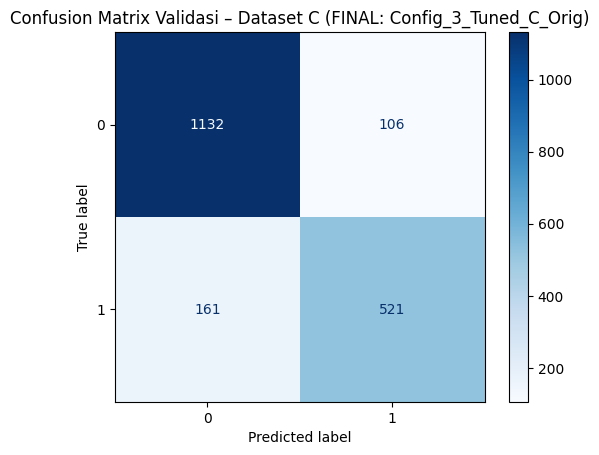

              precision    recall  f1-score   support

           0       0.88      0.91      0.89      1238
           1       0.83      0.76      0.80       682

    accuracy                           0.86      1920
   macro avg       0.85      0.84      0.85      1920
weighted avg       0.86      0.86      0.86      1920

Rekap eksperimen:


,dataset,config_name,seed,val_accuracy,val_error,training_time
0,C,Config_1_Baseline,42,0.85781,0.14219,24.39
1,C,Config_2_Deeper,42,0.85938,0.14062,15.57
2,C,Config_3_Tuned_C_Orig,42,0.86094,0.13906,19.42


Pembanding non-DL:


,dataset,model,val_accuracy,time_s
2,C,MLP terbaik – Config_3_Tuned_C_Orig,0.8609,NaN
0,C,RandomForest (pembanding),0.8448,2.4
1,C,XGBoost (pembanding),0.8432,0.4



Isi proyek:
  baseline_comparison_C.csv
  eda_summary_C.csv
  experiments.csv
  requirements.txt
  tuning_C_log.csv
  models/labelencoder_c.pkl
  models/model_c_best.keras
  models/preprocessor_c.pkl
  figures/cm_C.png
  figures/cm_C_final.png
  figures/eda_C.png
  figures/loss_C.png
  predictions/T017_C_01.csv


In [8]:
from importlib.metadata import version, PackageNotFoundError
lines = []
for p in ['tensorflow', 'scikit-learn', 'pandas', 'numpy', 'joblib', 'matplotlib', 'xgboost']:
    try: lines.append(f'{p}=={version(p)}')
    except PackageNotFoundError: pass
open(f'{PROJECT}/requirements.txt', 'w').write('\n'.join(lines) + '\n')
print(open(f'{PROJECT}/requirements.txt').read())

# Confusion matrix & classification report model final
final_vpred = (FINAL['model'].predict(d['Xval'], verbose=0).ravel() > 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(d['yval'], final_vpred)).plot(cmap='Blues')
plt.title(f"Confusion Matrix Validasi – Dataset C (FINAL: {FINAL['cfg']['name']})")
plt.savefig(f'{PROJECT}/figures/cm_C_final.png', dpi=150, bbox_inches='tight'); plt.show()
print(classification_report(d['yval'], final_vpred))

print('Rekap eksperimen:'); display(exp_df[['dataset', 'config_name', 'seed', 'val_accuracy', 'val_error', 'training_time']])
print('Pembanding non-DL:'); display(cmp_df)

print('\nIsi proyek:')
for root, _, files in os.walk(PROJECT):
    for f in sorted(files): print(' ', os.path.relpath(os.path.join(root, f), PROJECT))

## Fase 6 – Simpan ZIP

In [9]:
zip_base = f'/kaggle/working/{TEAM}_submission_C'
to_zip   = '/kaggle/working/zip_tmp'
shutil.rmtree(to_zip, ignore_errors=True); os.makedirs(to_zip)
for item in ['code', 'models', 'predictions', 'figures', 'requirements.txt', 'experiments.csv',
             'tuning_C_log.csv', 'baseline_comparison_C.csv', 'eda_summary_C.csv']:
    src = f'{PROJECT}/{item}'
    if os.path.isdir(src): shutil.copytree(src, f'{to_zip}/{item}')
    elif os.path.exists(src): shutil.copy(src, to_zip)
path = shutil.make_archive(zip_base, 'zip', to_zip)
print('ZIP dibuat:', path, f'({os.path.getsize(path)/1e6:.1f} MB)')

ZIP dibuat: /kaggle/working/T017_submission_C.zip (0.6 MB)
